# Examen parcial — versión 2

Identificamos vasos en imágenes de retina con dos métodos tradicionales.

## 1. Objetivo y protocolo

Usamos 45 imágenes de HRF. Elegimos parámetros con seis y comparamos los métodos en las otras 39. La división no es aleatoria.

La referencia manual sirve para evaluar; no se usa para crear las predicciones. Estos 39 casos ya se habían observado en V1: la comparación es exploratoria.

In [1]:
# Cargamos las librerías y buscamos la carpeta del trabajo.
from pathlib import Path
import csv
import json
import sys
import subprocess
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
opciones = [carpeta / relativa for carpeta in [Path.cwd(), *Path.cwd().parents]
            for relativa in ['.', 'version_1', 'version_2', 'examen parcial/version_1', 'examen parcial/version_2']]
base = next((carpeta for carpeta in opciones
             if (carpeta / 'configuracion/seleccion.json').is_file()
             and (carpeta / 'codigo/metodos.py').is_file()), None)
if base is None:
    raise FileNotFoundError('Abrir el notebook dentro de la carpeta de su versión.')
carpeta_datos = base / 'datos/HRF'
if not carpeta_datos.is_dir():
    carpeta_datos = base.parent / 'datos_compartidos/HRF'
if not carpeta_datos.is_dir():
    raise FileNotFoundError('Extraer HRF en datos_compartidos/HRF antes de ejecutar.')
print('Python:', sys.version.split()[0], '| OpenCV:', cv2.__version__, '| NumPy:', np.__version__)
print('Carpeta de trabajo:', base.name)

Python: 3.14.8 | OpenCV: 5.0.0 | NumPy: 2.5.5
Carpeta de trabajo: version_2


## 2. Parámetros fijados antes de evaluar

Leemos los valores guardados de la evaluación final. Se eligieron con seis imágenes y después quedaron fijos.

In [2]:
# Leemos los parámetros de la evaluación final.
configuracion = json.loads((base / 'resultados/evaluacion/seleccion.json').read_text())
parametros = configuracion['experimento']
display(Markdown('```json\n' + json.dumps(configuracion, indent=2, ensure_ascii=False) + '\n```'))

```json
{
  "experimento": {
    "ancho_procesamiento": 1800,
    "contraste_clahe": 2.0,
    "ventana_local": 47,
    "sigma_iluminacion": 25.0,
    "area_minima": 45,
    "margen_campo": 3,
    "casos_desarrollo": [
      "01_h",
      "02_h",
      "01_dr",
      "02_dr",
      "01_g",
      "02_g"
    ],
    "correcciones_a_comparar": [
      false,
      true
    ],
    "constantes_a_comparar": [
      6,
      8,
      10
    ],
    "umbrales_bajos_a_comparar": [
      5,
      7
    ],
    "umbrales_altos_a_comparar": [
      12,
      16
    ]
  },
  "corregir_iluminacion": false,
  "metodos": {
    "umbral_adaptativo": {
      "constante": 10
    },
    "crecimiento_regiones": {
      "umbral_bajo": 7,
      "umbral_alto": 16
    }
  }
}
```

## 3. Leer imagen, referencia y campo visual

Cargamos la fotografía, los vasos marcados manualmente y el campo visual. Revisamos que tengan el mismo tamaño. El ejemplo `01_h` es de desarrollo.

Casos disponibles: 45 | Dimensiones: (2336, 3504)


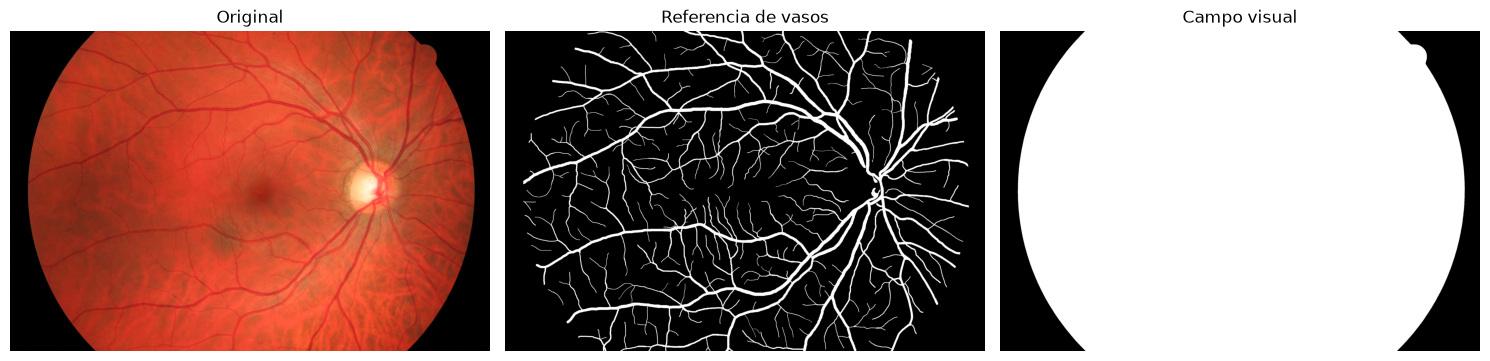

In [3]:
# Abrimos una imagen de ejemplo y revisamos su tamaño.
caso = '01_h'
rutas = [ruta for ruta in (carpeta_datos / 'images').iterdir()
         if ruta.suffix.lower() == '.jpg']
ruta_imagen = next(ruta for ruta in rutas if ruta.stem == caso)
imagen = cv2.imread(str(ruta_imagen), cv2.IMREAD_COLOR)
referencia_leida = cv2.imread(str(carpeta_datos / 'manual1' / f'{caso}.tif'), 0)
campo_leido = cv2.imread(str(carpeta_datos / 'mask' / f'{caso}_mask.tif'), 0)
if imagen is None or referencia_leida is None or campo_leido is None:
    raise ValueError('No se pudo leer el trío de archivos del caso.')
referencia = referencia_leida > 0
campo_visual = campo_leido > 0
assert imagen.shape[:2] == referencia.shape == campo_visual.shape
print('Casos disponibles:', len(rutas), '| Dimensiones:', imagen.shape[:2])

# Mostramos la imagen y sus dos máscaras.
figura, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, titulo, contenido in zip(ejes, ['Original', 'Referencia de vasos', 'Campo visual'],
                                 [cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), referencia, campo_visual]):
    eje.imshow(contenido, cmap='gray')
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.show()

## 4. Preparación compartida

Reducimos el ancho a 1800 y usamos el canal verde. Aplicamos CLAHE y un suavizado. La corrección adicional de iluminación quedó desactivada.

In [4]:
def preparar_imagen(imagen, campo_original, parametros, corregir_iluminacion):
    """Preparar la imagen para ambos métodos."""
    # Reducimos la imagen al ancho de trabajo.
    alto, ancho = imagen.shape[:2]
    escala = min(1.0, parametros['ancho_procesamiento'] / ancho)
    tamano = (round(ancho * escala), round(alto * escala))
    reducida = cv2.resize(imagen, tamano, interpolation=cv2.INTER_AREA)
    campo = cv2.resize(campo_original.astype(np.uint8), tamano,
                       interpolation=cv2.INTER_NEAREST).astype(bool)
    verde = reducida[:, :, 1]

    # Corregimos la iluminación solo si la opción está activada.
    # El fondo negro no participa en el cálculo.
    fondo = None
    if corregir_iluminacion:
        sigma = parametros['sigma_iluminacion']
        pesos = cv2.GaussianBlur(campo.astype(np.float32), (0, 0), sigma)
        suma = cv2.GaussianBlur(verde.astype(np.float32) * campo, (0, 0), sigma)
        fondo = suma / np.maximum(pesos, 1e-6)
        corregida = np.clip(verde.astype(np.float32) - fondo + 128, 0, 255).astype(np.uint8)
    else:
        corregida = verde.copy()
    corregida[~campo] = int(np.median(corregida[campo]))

    # Mejoramos el contraste y suavizamos el ruido.
    contraste = cv2.createCLAHE(clipLimit=parametros['contraste_clahe'],
                               tileGridSize=(8, 8)).apply(corregida)
    preparada = cv2.GaussianBlur(contraste, (3, 3), 0)
    preparada[~campo] = int(np.median(preparada[campo]))

    # Quitamos un borde pequeño para evitar detecciones del contorno.
    # Los vasos omitidos en ese borde sí cuentan como errores.
    margen = parametros['margen_campo']
    elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * margen + 1, 2 * margen + 1))
    campo_interior = cv2.erode(campo.astype(np.uint8), elemento).astype(bool)
    ventana = parametros['ventana_local']
    promedio = cv2.GaussianBlur(preparada.astype(np.float32), (ventana, ventana), 0)
    oscuridad_local = promedio - preparada.astype(np.float32)
    return {'verde': verde, 'fondo': fondo, 'corregida': corregida,
            'preparada': preparada, 'oscuridad_local': oscuridad_local,
            'campo_interior': campo_interior}

## 5. Crecimiento por conectividad 8

Conservamos los candidatos conectados a una semilla, incluidas las diagonales. Las semillas salen de la imagen, no de la referencia manual.

In [5]:
def crecer_desde_semillas(semillas, candidatos):
    """Conservar candidatos conectados a semillas por ocho vecinos."""
    # Nos quedamos con las regiones que tienen alguna semilla.
    candidatos = candidatos.astype(bool)
    semillas = semillas.astype(bool) & candidatos
    cantidad, etiquetas = cv2.connectedComponents(candidatos.astype(np.uint8), connectivity=8)
    conservar = np.zeros(cantidad, dtype=bool)
    conservar[np.unique(etiquetas[semillas])] = True
    conservar[0] = False
    return conservar[etiquetas]

## 6. Limpieza y resolución de salida

Quitamos componentes menores de 45 píxeles y volvemos al tamaño original. Esto puede borrar vasos finos y no recupera el detalle perdido.

In [6]:
def limpiar_y_restaurar(mascara, campo_interior, campo_original, parametros):
    """Quitar puntos pequeños y recuperar el tamaño original."""
    mascara = (mascara & campo_interior).astype(np.uint8)
    cantidad, etiquetas, estadisticas, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    conservar = np.zeros(cantidad, dtype=bool)
    conservar[1:] = estadisticas[1:, cv2.CC_STAT_AREA] >= parametros['area_minima']
    limpia = conservar[etiquetas].astype(np.uint8)
    alto, ancho = campo_original.shape
    original = cv2.resize(limpia, (ancho, alto), interpolation=cv2.INTER_NEAREST).astype(bool)
    return original & campo_original

## 7. Dos decisiones de segmentación

**Adaptativo:** compara cada píxel con su entorno.

**Crecimiento:** además exige conexión con una semilla.

In [7]:
def segmentar(etapas, campo_original, parametros, metodo, configuracion):
    """Aplicar el método elegido."""
    campo = etapas['campo_interior']
    if metodo == 'umbral_adaptativo':
        # Marcamos los píxeles oscuros respecto a su entorno.
        mascara = cv2.adaptiveThreshold(
            etapas['preparada'], 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV, parametros['ventana_local'], configuracion['constante']) > 0
        intermedias = {'umbral_inicial': mascara & campo}
    elif metodo == 'crecimiento_regiones':
        # Separamos las semillas de los posibles vasos.
        # Después conservamos los candidatos conectados a semillas.
        bajo, alto = configuracion['umbral_bajo'], configuracion['umbral_alto']
        if bajo >= alto:
            raise ValueError('El umbral de semillas debe superar al de candidatos.')
        semillas = (etapas['oscuridad_local'] >= alto) & campo
        candidatos = (etapas['oscuridad_local'] >= bajo) & campo
        mascara = crecer_desde_semillas(semillas, candidatos)
        intermedias = {'semillas': semillas, 'candidatos': candidatos, 'region_crecida': mascara}
    else:
        raise ValueError(f'Método desconocido: {metodo}')
    prediccion = limpiar_y_restaurar(mascara, campo, campo_original, parametros)
    return prediccion, intermedias

## Ejecución del ejemplo y pasos intermedios

Aplicamos ambos métodos al mismo caso. Mostramos la preparación, las semillas, los candidatos y las máscaras.

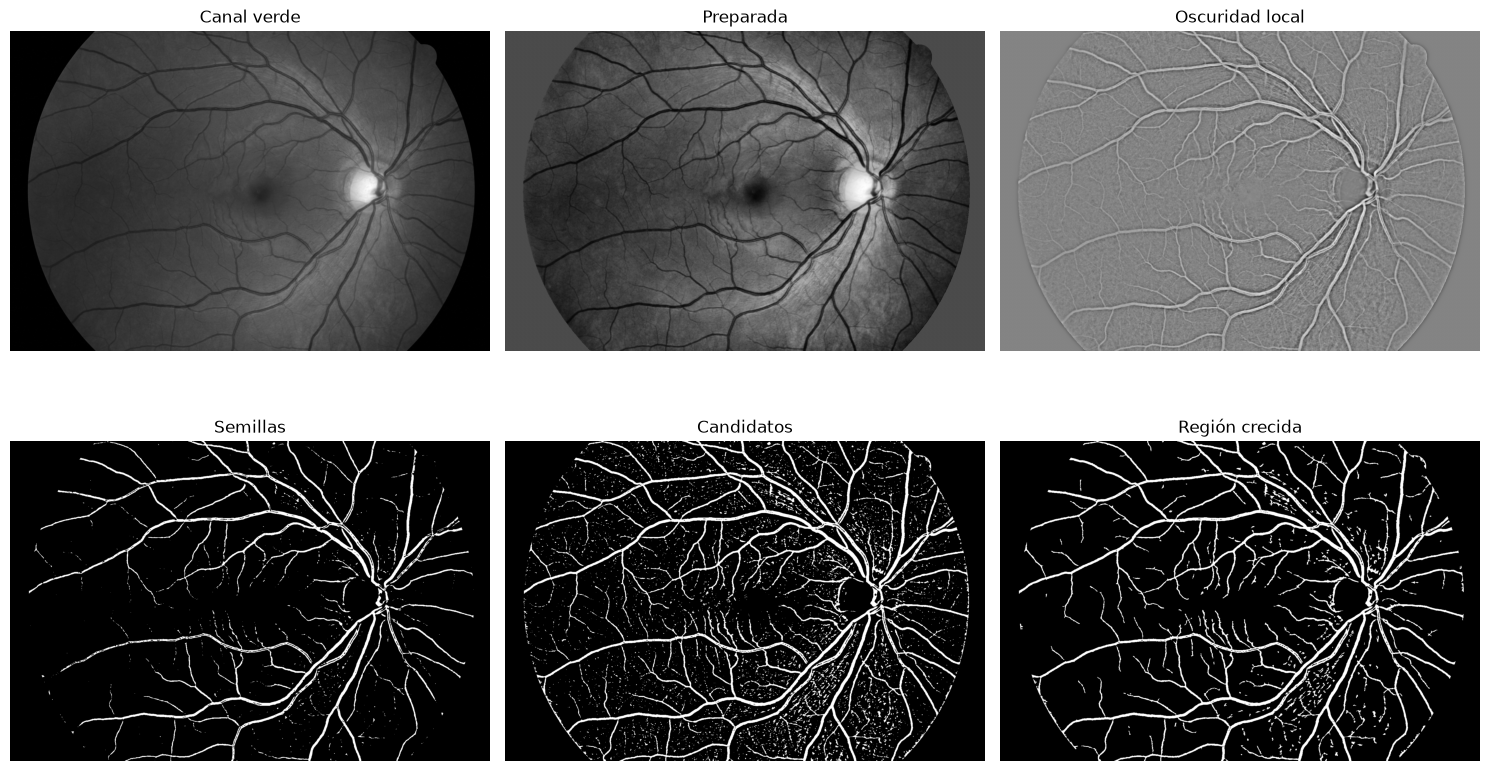

In [8]:
# Preparamos la imagen y aplicamos ambos métodos.
etapas = preparar_imagen(imagen, campo_visual, parametros, configuracion['corregir_iluminacion'])
salidas, pasos = {}, {}
for metodo, valores in configuracion['metodos'].items():
    salidas[metodo], pasos[metodo] = segmentar(etapas, campo_visual, parametros, metodo, valores)

# Mostramos los pasos antes de limpiar la máscara.
contenidos = [('Canal verde', etapas['verde']), ('Preparada', etapas['preparada']),
              ('Oscuridad local', etapas['oscuridad_local']),
              ('Semillas', pasos['crecimiento_regiones']['semillas']),
              ('Candidatos', pasos['crecimiento_regiones']['candidatos']),
              ('Región crecida', pasos['crecimiento_regiones']['region_crecida'])]
figura, ejes = plt.subplots(2, 3, figsize=(15, 9))
for eje, (titulo, contenido) in zip(ejes.flat, contenidos):
    eje.imshow(contenido, cmap='gray')
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.show()

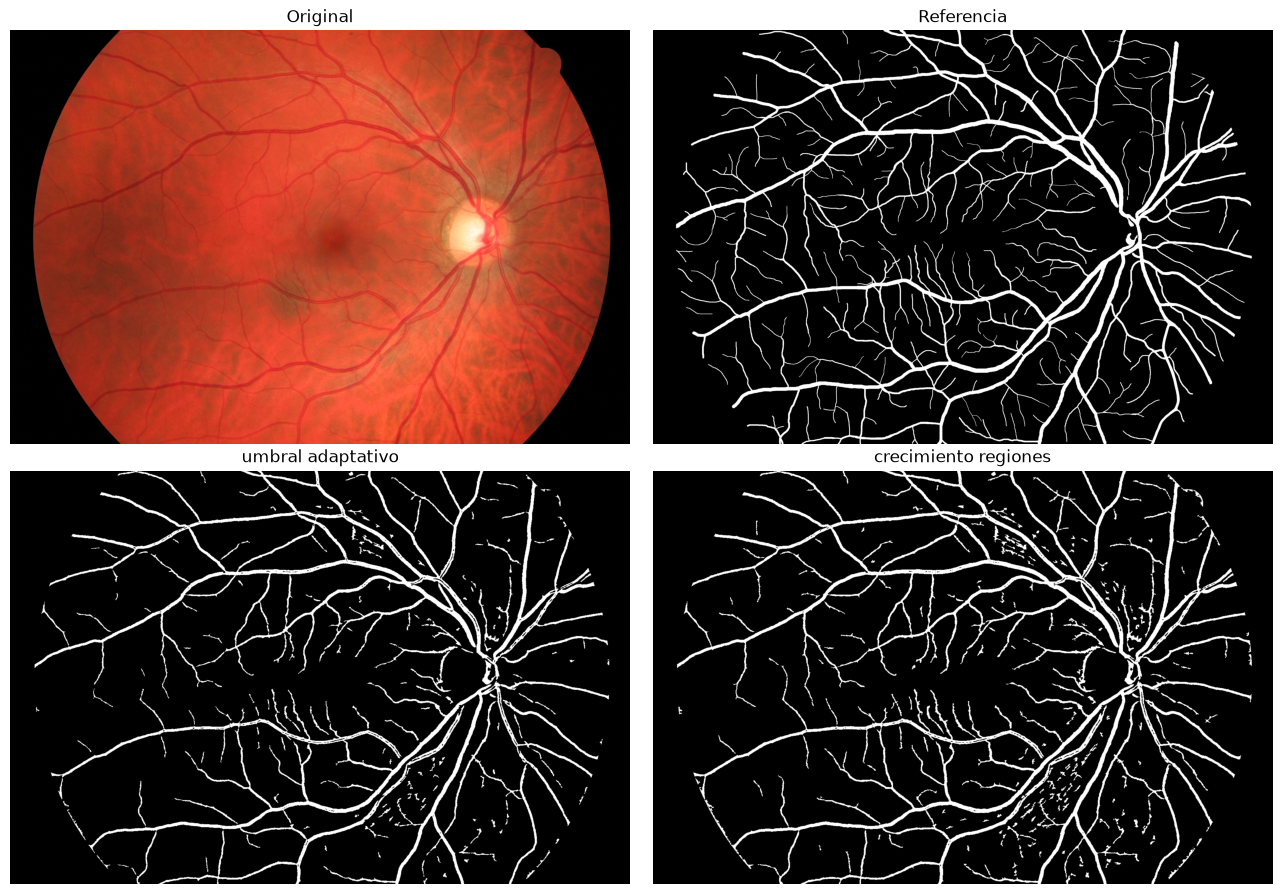

In [9]:
# Comparamos ambas predicciones con la misma referencia.
contenidos = [('Original', cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)), ('Referencia', referencia)]
contenidos += [(nombre.replace('_', ' '), mascara) for nombre, mascara in salidas.items()]
figura, ejes = plt.subplots(2, 2, figsize=(13, 9))
for eje, (titulo, contenido) in zip(ejes.flat, contenidos):
    eje.imshow(contenido, cmap='gray')
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.show()

## Métricas y comprobación contra los PNG guardados

Dice e IoU miden la coincidencia con la referencia. Un valor de uno indica coincidencia perfecta. Evaluamos dentro de todo el campo original y revisamos los PNG guardados.

In [10]:
def calcular_metricas(prediccion, referencia, campo):
    """Calcular Dice e IoU dentro del campo original."""
    predicha, real = prediccion[campo], referencia[campo]
    vp = int(np.count_nonzero(predicha & real))
    fp = int(np.count_nonzero(predicha & ~real))
    fn = int(np.count_nonzero(~predicha & real))
    denominador_dice, denominador_iou = 2 * vp + fp + fn, vp + fp + fn
    return {'dice': 2 * vp / denominador_dice if denominador_dice else 1.0,
            'iou': vp / denominador_iou if denominador_iou else 1.0,
            'verdaderos_positivos': vp, 'falsos_positivos': fp, 'falsos_negativos': fn}

In [11]:
# Revisamos que el resultado coincida con las máscaras guardadas.
for nombre, prediccion in salidas.items():
    guardada = cv2.imread(str(base / 'predicted_masks' / nombre / f'{caso}.png'), 0)
    if guardada is None or not np.array_equal(prediccion, guardada > 0):
        raise ValueError(f'El notebook no coincide con la máscara guardada: {nombre}')
    resultado = calcular_metricas(prediccion, referencia, campo_visual)
    print(nombre, '| Dice:', round(resultado['dice'], 4), '| IoU:', round(resultado['iou'], 4))
print('Ambos métodos coinciden exactamente con los PNG del caso de desarrollo.')

umbral_adaptativo | Dice: 0.7667 | IoU: 0.6216
crecimiento_regiones | Dice: 0.7713 | IoU: 0.6277
Ambos métodos coinciden exactamente con los PNG del caso de desarrollo.


## Ajuste registrado y resultados finales

La tabla de ajuste usa seis imágenes. La comparación final usa las otras 39. Cada imagen tiene el mismo peso.

In [12]:
# Mostramos los resultados en tablas.
def mostrar_tabla(ruta, filtro=None, columnas=None):
    with ruta.open() as archivo:
        filas = [fila for fila in csv.DictReader(archivo) if filtro is None or filtro(fila)]
    columnas = columnas or list(filas[0])
    lineas = ['| ' + ' | '.join(columnas) + ' |', '| ' + ' | '.join(['---'] * len(columnas)) + ' |']
    for fila in filas:
        valores = []
        for columna in columnas:
            valor = fila[columna]
            if columna.startswith(('dice', 'iou')):
                valor = f'{float(valor):.4f}'
            valores.append(valor)
        lineas.append('| ' + ' | '.join(valores) + ' |')
    display(Markdown('\n'.join(lineas)))

mostrar_tabla(base / 'resultados/ajuste/resumen.csv')
display(Markdown('### Comparación principal: 39 casos'))
mostrar_tabla(base / 'resultados/evaluacion/resumen.csv',
              filtro=lambda fila: fila['particion'] == 'evaluacion' and fila['grupo'] == 'todos')
display(Markdown('### Desglose por grupo clínico'))
mostrar_tabla(base / 'resultados/evaluacion/resumen.csv',
              filtro=lambda fila: fila['particion'] == 'evaluacion' and fila['grupo'] != 'todos',
              columnas=['metodo', 'grupo', 'cantidad', 'dice_promedio', 'iou_promedio'])

| candidato | metodo | corregir_iluminacion | dice_promedio | iou_promedio |
| --- | --- | --- | --- | --- |
| adaptativo_0_6 | umbral_adaptativo | False | 0.6697 | 0.5076 |
| adaptativo_0_8 | umbral_adaptativo | False | 0.7118 | 0.5559 |
| adaptativo_0_10 | umbral_adaptativo | False | 0.7198 | 0.5652 |
| regiones_0_5_12 | crecimiento_regiones | False | 0.6674 | 0.5050 |
| regiones_0_5_16 | crecimiento_regiones | False | 0.6922 | 0.5332 |
| regiones_0_7_12 | crecimiento_regiones | False | 0.7064 | 0.5496 |
| regiones_0_7_16 | crecimiento_regiones | False | 0.7155 | 0.5605 |
| adaptativo_1_6 | umbral_adaptativo | True | 0.6628 | 0.5000 |
| adaptativo_1_8 | umbral_adaptativo | True | 0.7095 | 0.5531 |
| adaptativo_1_10 | umbral_adaptativo | True | 0.7198 | 0.5652 |
| regiones_1_5_12 | crecimiento_regiones | True | 0.6602 | 0.4971 |
| regiones_1_5_16 | crecimiento_regiones | True | 0.6878 | 0.5280 |
| regiones_1_7_12 | crecimiento_regiones | True | 0.7037 | 0.5462 |
| regiones_1_7_16 | crecimiento_regiones | True | 0.7123 | 0.5564 |

### Comparación principal: 39 casos

| particion | metodo | grupo | cantidad | dice_promedio | dice_desviacion | iou_promedio | iou_desviacion |
| --- | --- | --- | --- | --- | --- | --- | --- |
| evaluacion | umbral_adaptativo | todos | 39 | 0.7116 | 0.0587 | 0.5554 | 0.0698 |
| evaluacion | crecimiento_regiones | todos | 39 | 0.7152 | 0.0670 | 0.5607 | 0.0796 |

### Desglose por grupo clínico

| metodo | grupo | cantidad | dice_promedio | iou_promedio |
| --- | --- | --- | --- | --- |
| umbral_adaptativo | h | 13 | 0.7666 | 0.6225 |
| umbral_adaptativo | dr | 13 | 0.6565 | 0.4904 |
| umbral_adaptativo | g | 13 | 0.7118 | 0.5534 |
| crecimiento_regiones | h | 13 | 0.7807 | 0.6411 |
| crecimiento_regiones | dr | 13 | 0.6478 | 0.4816 |
| crecimiento_regiones | g | 13 | 0.7171 | 0.5594 |

## Ejemplos favorables y difíciles

Mostramos los casos de mayor y menor Dice del crecimiento entre los 39. En cada caso se ven ambos métodos.

**mayor dice regiones 11 h**

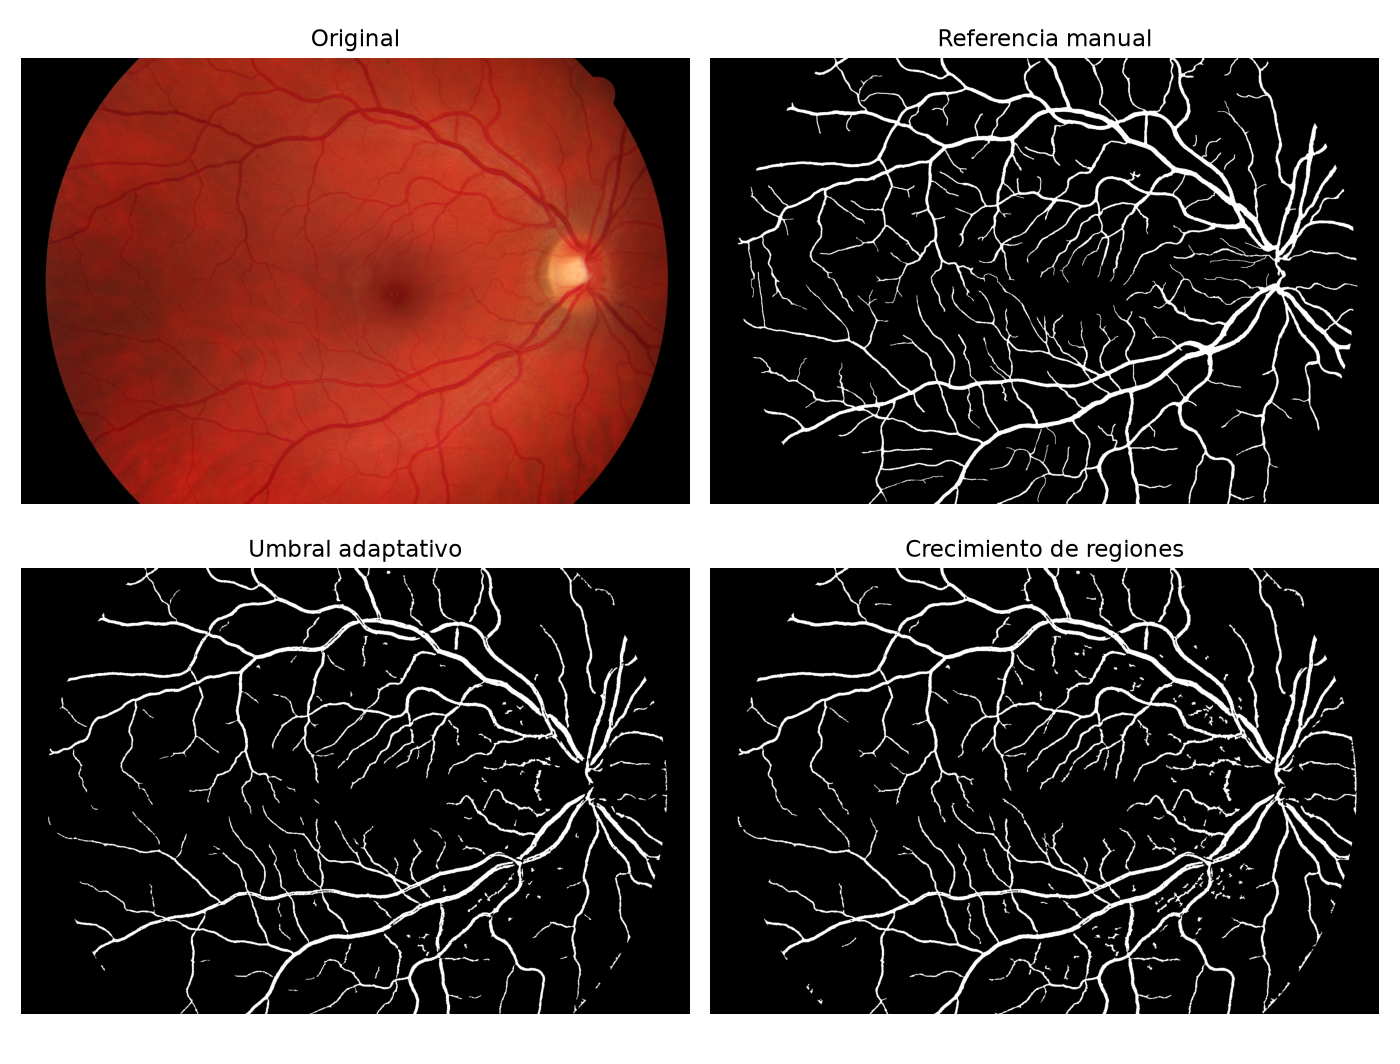

**menor dice regiones 03 dr**

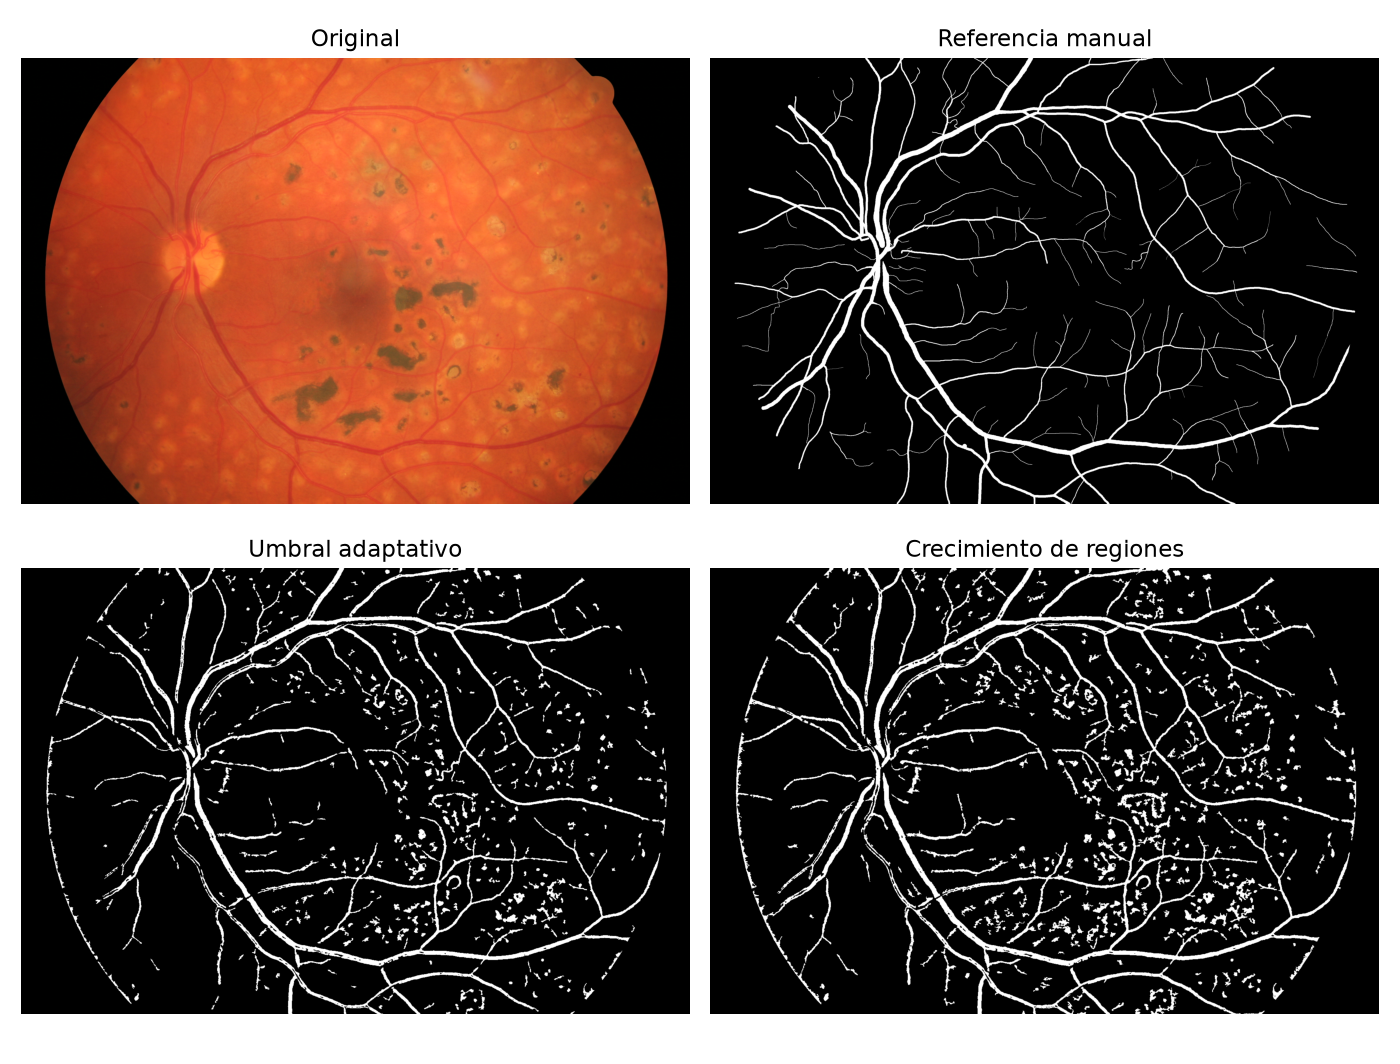

In [13]:
# Abrimos un ejemplo favorable y uno difícil.
from IPython.display import Image as ImagenMostrada
for patron in ['mayor_dice_regiones_*.png', 'menor_dice_regiones_*.png']:
    ruta_figura = next((base / 'resultados/evaluacion').glob(patron))
    display(Markdown('**' + ruta_figura.stem.replace('_', ' ') + '**'))
    display(ImagenMostrada(filename=str(ruta_figura), width=1000))

## Reproducir el lote completo (opcional)

Dejamos esta opción desactivada para conservar los resultados. Activarla vuelve a generar las 90 máscaras con los mismos parámetros.

In [14]:
# Cambiar a True solo para volver a generar todas las máscaras.
recalcular_todo = False
if recalcular_todo:
    subprocess.run([sys.executable, str(base / 'codigo/ejecutar.py')], check=True)
    subprocess.run([sys.executable, str(base / 'codigo/resumir.py')], check=True)
    subprocess.run([sys.executable, str(base / 'codigo/verificar.py')], check=True)
else:
    print('Se conservan las máscaras y las métricas finales existentes.')

Se conservan las máscaras y las métricas finales existentes.


## Conclusiones y limitaciones

Dice medio: **0,7116** para adaptativo y **0,7152** para crecimiento. El mejor V1 fue **0,7158**.

Ambos omiten vasos finos y producen falsas detecciones. El ajuste usa pocos casos y la comparación reutiliza la partición de V1.